# Bootstrapping Results for Walloon Models

## Libraries

In [1]:
#%pip install pesq
#%pip install pymcd
#%pip install torch
#%pip install torchmetrics
#%pip install huggingface_hub
#%pip install numpy < 2.0.0

In [ ]:
import os
import numpy as np
import torch
import librosa
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils import resample
from metrics_utils.metrics_script import calculate_mcd, calculate_pesq, calculate_cosine_similarity
from pymcd.mcd import Calculate_MCD
from torchmetrics.audio import PerceptualEvaluationSpeechQuality
from huggingface_hub import hf_hub_download

ecapa2.pt:   0%|          | 0.00/109M [00:00<?, ?B/s]

c:\Users\felip\miniconda3\envs\metrics\lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\felip\.cache\huggingface\hub\models--Jenthe--ECAPA2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## Bootstrap Code

In [3]:
def bootstrap(data, n_bootstrap, ci):
    """
    Perform bootstrapping on the data to estimate the confidence interval of the mean.
    :param data: The data to perform bootstrapping on.
    :param n_bootstrap: The number of bootstrap samples to generate.
    :param ci: The confidence interval to estimate.
    :return: The mean of the data, the lower bound of the confidence interval, and the upper bound of the confidence interval.
    """
    # Initialize the list of bootstrap statistics
    sample_size = len(data)
    bootstrap_means = []

    # Perform bootstrapping
    for _ in range(n_bootstrap):
        resampled = resample(data, replace=True, n_samples=sample_size)
        bootstrap_means.append(np.mean(resampled))
    lower_bound = np.percentile(bootstrap_means, (100 - ci) / 2)
    upper_bound = np.percentile(bootstrap_means, 100 - (100 - ci) / 2)

    return lower_bound, upper_bound

def store_results(model, voice, metric, mean_value, lower_bound, upper_bound):
    if model not in results:
        results[model] = {}
    if voice not in results[model]:
        results[model][voice] = {}
    
    results[model][voice][metric] = {
        "mean": mean_value,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound
    }

def run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci):
    mcd_values, mean_mcd, _ = calculate_mcd(true_audio_folder, generated_audio_folder, report_file_path_mcd)
    pesq_values, mean_pesq, _ = calculate_pesq(true_audio_folder, generated_audio_folder, report_file_path_pesq)
    secs_values, mean_cosine, _ = calculate_cosine_similarity(true_audio_folder, generated_audio_folder, report_file_path_cosine)

    lower_bound_mcd, upper_bound_mcd = bootstrap(mcd_values, n_bootstrap, ci)
    lower_bound_pesq, upper_bound_pesq = bootstrap(pesq_values, n_bootstrap, ci)
    lower_bound_secs, upper_bound_secs = bootstrap(secs_values, n_bootstrap, ci)

    store_results(model, voice, "MCD", mean_mcd, lower_bound_mcd, upper_bound_mcd)
    store_results(model, voice, "PESQ", mean_pesq, lower_bound_pesq, upper_bound_pesq)
    store_results(model, voice, "SECS", mean_cosine, lower_bound_secs, upper_bound_secs)

To do boostrapping We followed these steps:

1. Calculate the metrics for the entire test set for each model and save it in a list.
2. Resample this list with replacement.
3. Calculate the metrics for each sample.
4. After that, calculate the confident interval

In [4]:
n_bootstrap = 1000
ci = 95
results = {}

## Grapheme Based Model - Walloon Dataset Only

### Male Voice

In [5]:
model = "Wa_g"
voice = "Male"
true_audio_folder = 'grap_w_v1/male_true'
generated_audio_folder = 'grap_w_v1/male_gen'
report_file_path_mcd = "grap_w_v1/results_MCD_m.txt"
report_file_path_pesq = "grap_w_v1/results_PESQ_m.txt"
report_file_path_cosine = "grap_w_v1/results_SECS_m.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

### Female Voice

In [7]:
model = "Wa_g"
voice = "Female"
true_audio_folder = 'grap_w_v1/female_true'
generated_audio_folder = 'grap_w_v1/female_gen'
report_file_path_mcd = "grap_w_v1/results_MCD_f.txt"
report_file_path_pesq = "grap_w_v1/results_PESQ_f.txt"
report_file_path_cosine = "grap_w_v1/results_SECS_f.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

## Grapheme Based Model - French and Walloon Dataset

### Male Voice

In [8]:
model = "Fr_g"
voice = "Male"
true_audio_folder = 'grap_ft_v1/male_true'
generated_audio_folder = 'grap_ft_v1/male_gen'
report_file_path_mcd = "grap_ft_v1/results_MCD_m.txt"
report_file_path_pesq = "grap_ft_v1/results_PESQ_m.txt"
report_file_path_cosine = "grap_ft_v1/results_SECS_m.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

### Female Voice

In [9]:
model = "Fr_g"
voice = "Female"
true_audio_folder = 'grap_ft_v1/female_true'
generated_audio_folder = 'grap_ft_v1/female_gen'
report_file_path_mcd = "grap_ft_v1/results_MCD_f.txt"
report_file_path_pesq = "grap_ft_v1/results_PESQ_f.txt"
report_file_path_cosine = "grap_ft_v1/results_SECS_f.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

## Phonemes Based Model - Walloon Dataset Only

### Male Voice

In [10]:
model = "Wa_p"
voice = "Male"
true_audio_folder = 'pho_w/male_true'
generated_audio_folder = 'pho_w/male_gen'
report_file_path_mcd = "pho_w/results_MCD_m.txt"
report_file_path_pesq = "pho_w/results_PESQ_m.txt"
report_file_path_cosine = "pho_w/results_SECS_m.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

### Female Voice

In [11]:
model = "Wa_p"
voice = "Female"
true_audio_folder = 'pho_w/female_true'
generated_audio_folder = 'pho_w/female_gen'
report_file_path_mcd = "pho_w/results_MCD_f.txt"
report_file_path_pesq = "pho_w/results_PESQ_f.txt"
report_file_path_cosine = "pho_w/results_SECS_f.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

## Phonemes Based Model - French and Walloon Dataset

### Male Voice

In [12]:
model = "Fr_p"
voice = "Male"
true_audio_folder = 'pho_ft/male_true'
generated_audio_folder = 'pho_ft/male_gen'
report_file_path_mcd = "pho_ft/results_MCD_m.txt"
report_file_path_pesq = "pho_ft/results_PESQ_m.txt"
report_file_path_cosine = "pho_ft/results_SECS_m.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

### Female Voice

In [13]:
model = "Fr_p"
voice = "Female"
true_audio_folder = 'pho_ft/female_true'
generated_audio_folder = 'pho_ft/female_gen'
report_file_path_mcd = "pho_ft/results_MCD_f.txt"
report_file_path_pesq = "pho_ft/results_PESQ_f.txt"
report_file_path_cosine = "pho_ft/results_SECS_f.txt"

run_tests(model, voice, true_audio_folder, generated_audio_folder, report_file_path_mcd, report_file_path_pesq, report_file_path_cosine, n_bootstrap, ci)

## Results

In [ ]:
# to save results (optional)

#import json
#with open('results_last_version.json', 'w') as f:
#    json.dump(results, f)

In [ ]:
# Function to create bar plots
def create_bar_plot(data, title, metric, models, voices, ylabel):
    fig, ax = plt.subplots()

    means = [data[model][voice][metric]["mean"] for model in models for voice in voices]
    lower_bounds = [data[model][voice][metric]["lower_bound"] for model in models for voice in voices]
    upper_bounds = [data[model][voice][metric]["upper_bound"] for model in models for voice in voices]
    yerr_lower = np.array(means) - np.array(lower_bounds)
    yerr_upper = np.array(upper_bounds) - np.array(means)
    
    colors = plt.cm.Set3(np.linspace(0, 1, len(models)))  
    alpha = 0.7  

    x_labels = [model for model in models] 
    x_pos = np.arange(len(x_labels))
    bars = ax.bar(x_pos, means, yerr=[yerr_lower, yerr_upper], capsize=5, color=colors, alpha=alpha)

    # Adjust Y-axis scale dynamically based on data range
    
    y_min = min(means) - max(yerr_lower) * 1.5  # change here the margin
    y_max = max(means) + max(yerr_upper) * 1.5  # change here the margin
    ax.set_ylim([y_min, y_max])
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=45, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

In [ ]:
# List of models and voices to compare
models = ["Fr_g", "Fr_p", "Wa_g", "Wa_p"]
voices_male = ["Male"]
voices_female = ["Female"]

In [ ]:
# Function to create grouped bar plots comparing male and female voices
def create_grouped_bar_plot(data, title, metric, models, ylabel):
    fig, ax = plt.subplots()

    means_male = [data[model]["Male"][metric]["mean"] for model in models]
    means_female = [data[model]["Female"][metric]["mean"] for model in models]
    
    lower_bounds_male = [data[model]["Male"][metric]["lower_bound"] for model in models]
    upper_bounds_male = [data[model]["Male"][metric]["upper_bound"] for model in models]
    
    lower_bounds_female = [data[model]["Female"][metric]["lower_bound"] for model in models]
    upper_bounds_female = [data[model]["Female"][metric]["upper_bound"] for model in models]

    # Calculate error bars
    yerr_lower_male = np.array(means_male) - np.array(lower_bounds_male)
    yerr_upper_male = np.array(upper_bounds_male) - np.array(means_male)
    
    yerr_lower_female = np.array(means_female) - np.array(lower_bounds_female)
    yerr_upper_female = np.array(upper_bounds_female) - np.array(means_female)

    # Bar width and positions
    bar_width = 0.35  # Width of the bars
    x_pos = np.arange(len(models))  # Positions of the groups
    offset = bar_width / 2 # Offset for male and female bars

    # Set colors with transparency
    colors_male = plt.cm.Set2(0)
    colors_female = plt.cm.Set2(1)
    alpha = 0.7

    ax.bar(x_pos - offset, means_male, yerr=[yerr_lower_male, yerr_upper_male], capsize=5, width=bar_width, color=colors_male, alpha=alpha, label='Male')
    ax.bar(x_pos + offset, means_female, yerr=[yerr_lower_female, yerr_upper_female], capsize=5, width=bar_width, color=colors_female, alpha=alpha, label='Female')

    # Adjust Y-axis scale dynamically with 5% margin
    y_min = min(min(means_male), min(means_female)) - max(max(yerr_lower_male), max(yerr_lower_female)) * 2
    y_max = max(max(means_male), max(means_female)) + max(max(yerr_upper_male), max(yerr_upper_female)) * 1.3
    ax.set_ylim([y_min, y_max])

    # add grid
    ax.grid(True, linestyle='--', alpha=0.7)

    # Labeling
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=0, ha="right")
    plt.title(title)

    ax.legend()
    plt.savefig(f"{title}.pdf", bbox_inches='tight')
    plt.tight_layout()
    plt.show()

In [ ]:
#import json

# Load the JSON file into a variable
#with open('results_last_version.json', 'r') as f:
#    results = json.load(f)

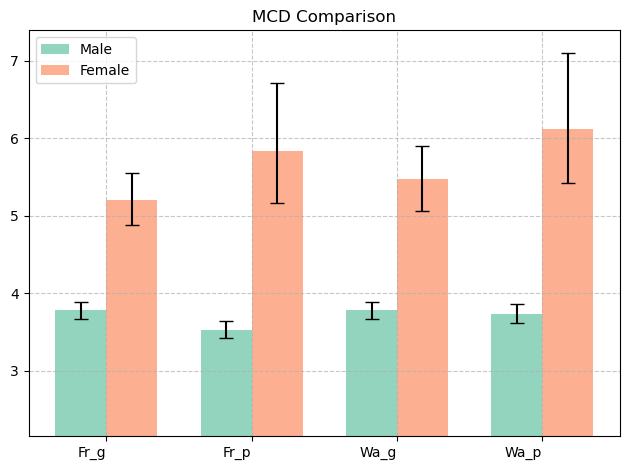

In [5]:
# Plot for male and female comparison for each metric
create_grouped_bar_plot(results, "MCD Comparison", "MCD", models, "MCD Score")

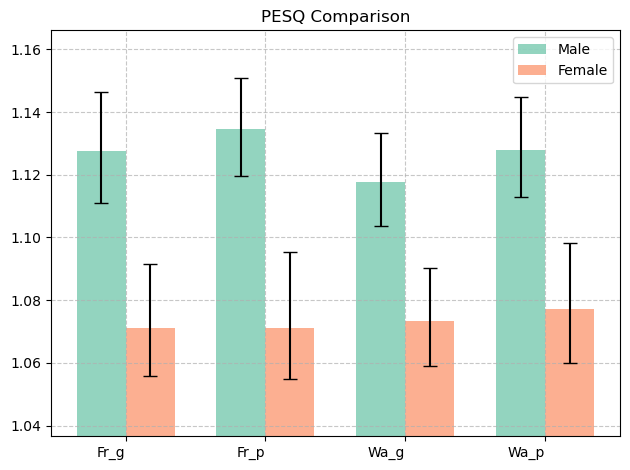

In [6]:
create_grouped_bar_plot(results, "PESQ Comparison", "PESQ", models, "PESQ Score")

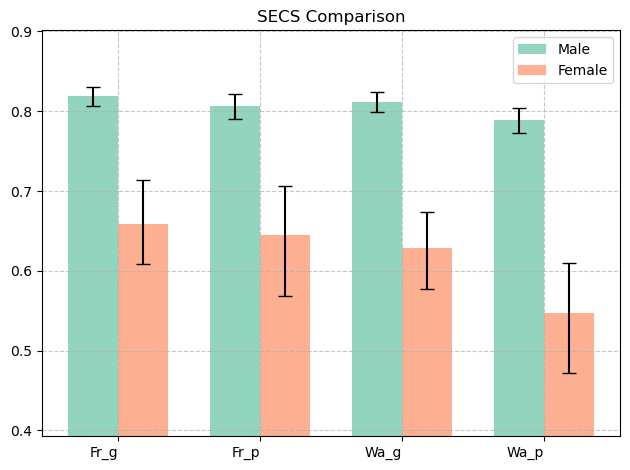

In [7]:
create_grouped_bar_plot(results, "SECS Comparison", "SECS", models, "SECS Score")